# Phenotypic assortment and the evolution of cooperation in finite periodic phenotype spaces

**Dhaker Kroumi · Code and data, version 1.0.0**

Run all cells to reproduce `fig1`, `fig2`, `fig3`, `fig4`, `fig5`,
`fig5_threshold_vs_n`, and `fig7_threshold_vs_L`.
The figures (PNG and PDF), numerical data, and checks are saved in `results/`.
The supplied outputs are in `reference_results/`. No input data files are needed.

The threshold is written $(b/c)^{*}_{n}(\alpha)$ throughout.
$L$, $\mu$, and $\nu$ remain model parameters; they are not included in its notation.

Install the packages listed in `requirements.txt` before running this notebook.
See `README.txt` for the command-line option.


In [1]:
%matplotlib inline
from pathlib import Path
from io import BytesIO
import json
import csv
import sys
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(globals().get('RUN_OUTPUT_DIR', Path.cwd() / 'results'))
FIGURE_DIR = OUTPUT_DIR / 'figures'
DATA_DIR = OUTPUT_DIR / 'data'
CHECK_DIR = OUTPUT_DIR / 'checks'
for directory in (FIGURE_DIR, DATA_DIR, CHECK_DIR):
    directory.mkdir(parents=True, exist_ok=True)
DATA_TABLES = {}


def write_data(name, columns, rows):
    rows = list(rows)
    with (DATA_DIR / name).open('w', newline='', encoding='utf-8') as stream:
        writer = csv.writer(stream)
        writer.writerow(columns)
        writer.writerows(rows)
    DATA_TABLES[name] = {'columns': list(columns), 'rows': len(rows)}


THRESHOLD_COLUMNS = ('L', 'n', 'alpha', 'mu', 'nu', 'threshold')

plt.rcParams.update({
    'font.family': 'STIXGeneral', 'font.size': 9,
    'mathtext.fontset': 'stix', 'mathtext.rm': 'STIXGeneral',
    'mathtext.it': 'STIXGeneral:italic', 'mathtext.bf': 'STIXGeneral:bold',
    'axes.labelsize': 10, 'axes.titlesize': 10, 'axes.linewidth': 0.9,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': True, 'ytick.right': True,
    'legend.fontsize': 9, 'legend.frameon': True,
    'lines.linewidth': 2.0, 'lines.markersize': 6,
    'figure.dpi': 100, 'savefig.dpi': 400,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})
COLORS = ['#1b4f72','#e67e22','#27ae60','#8e44ad','#c0392b','#2980b9']
TICK_IN = dict(direction='in',top=True,right=True)

def save_figure(fig, name):
    # Render into memory before replacing each output file atomically.
    for extension in ('png', 'pdf'):
        with BytesIO() as buffer:
            fig.savefig(buffer, format=extension, dpi=400, bbox_inches='tight')
            target = FIGURE_DIR / f'{name}.{extension}'
            temporary = target.with_suffix(target.suffix + '.tmp')
            temporary.write_bytes(buffer.getvalue())
            temporary.replace(target)
    print(f'Saved {name}.png and {name}.pdf')

print('Ready to save figures, data, and numerical checks.')


No event loop hook running.
Ready to save figures, data, and numerical checks.


## Numerical method

The calculations use the finite Fourier expression for the periodic phenotype space.
Modes with the same rate are combined using their multiplicities. The threshold
$(b/c)^{*}_{n}(\alpha)$ is evaluated as a ratio of nonnegative sums.

For $L=100$ and $n=4,\ldots,10$, direct enumeration is too large.
A convergent algebraic series evaluates the same finite sum with a relative
truncation bound below $10^{-12}$. These bounds do not include floating-point rounding.
The figures are generated without quadrature; adaptive integration is used only
for independent checks. Formulas and error bounds are in `numerical_notes.pdf`
and its LaTeX source.


In [2]:
import math
from collections import Counter
from functools import lru_cache
from itertools import combinations_with_replacement

from scipy.stats import binom

# All production calculations start from the finite periodic Fourier spectrum.
# No Gauss--Laguerre or adaptive quadrature is used to generate the figures.
DIRECT_MAX_TERMS = 200_000
SERIES_REL_TOL = 1e-12
SERIES_CERTIFICATES = {}
METHOD_COUNTS = Counter()


def _check_parameters(alpha, L, n=1):
    if not np.isfinite(alpha) or alpha <= 0:
        raise ValueError('alpha must be finite and positive.')
    if int(L) != L or L < 2 or int(n) != n or n < 1:
        raise ValueError('L >= 2 and n >= 1 must be integers.')


@lru_cache(maxsize=256)
def _precompute(L, alpha):
    """Exact finite DFT, subject only to floating-point rounding."""
    m = np.arange(L)
    kernel = np.exp(-alpha * np.minimum(m, L-m))
    ph = np.fft.fft(kernel).real
    if np.any(ph < -5e-13):
        raise ArithmeticError('Unexpected negative Fourier coefficient.')
    ph = np.maximum(ph, 0.0)  # roundoff safeguard, not spectral truncation
    rates = 1.0 - np.cos(2*np.pi*np.arange(L)/L)
    return ph, rates


def _one_coordinate_spectrum(alpha, L):
    """Combine p and L-p: equal rates and equal Fourier coefficients."""
    ph, _ = _precompute(L, alpha)
    p = np.arange(L//2+1)
    multiplicity = np.full(p.size, 2.0)
    multiplicity[0] = 1.0
    if L % 2 == 0:
        multiplicity[-1] = 1.0
    rates = 1.0-np.cos(2*np.pi*p/L)
    weights = multiplicity*ph[p]/L
    if not np.isclose(weights.sum(), 1.0, rtol=0, atol=1e-12):
        raise ArithmeticError('Spectral probability weights do not sum to one.')
    weights /= weights.sum()  # removes accumulated floating-point normalization error
    return rates, weights


def grouped_term_count(L, n):
    return math.comb(n+L//2, n)


@lru_cache(maxsize=64)
def _grouped_geometry(L, n):
    """Regroup all L**n ordered modes by their occupation numbers."""
    g = L//2+1
    tuples = list(combinations_with_replacement(range(g), n))
    indices = np.asarray(tuples, dtype=np.int32)
    coefficients = np.asarray([
        math.factorial(n)/math.prod(math.factorial(k) for k in Counter(row).values())
        for row in tuples
    ], dtype=float)
    return indices, coefficients


@lru_cache(maxsize=256)
def grouped_spectrum(alpha, L, n):
    """Exact multinomial regrouping; no Fourier mode is discarded."""
    if grouped_term_count(L, n) > DIRECT_MAX_TERMS:
        raise ValueError('Spectrum exceeds the direct-sum budget; use the bounded algebraic evaluator.')
    rates1, weights1 = _one_coordinate_spectrum(alpha, L)
    indices, coefficients = _grouped_geometry(L, n)
    rates = rates1[indices].sum(axis=1)
    weights = coefficients*np.prod(weights1[indices], axis=1)
    if not np.isclose(weights.sum(), 1.0, rtol=0, atol=2e-12):
        raise ArithmeticError('Multinomial weights do not sum to one.')
    return rates, weights


@lru_cache(maxsize=64)
def _binomial_rows(j, K):
    k = np.arange(K+1)[:, None]
    i = np.arange(K+1)[None, :]
    rows = binom.pmf(i, k, (j-1)/j)
    rows /= rows.sum(axis=1, keepdims=True)
    return rows


@lru_cache(maxsize=128)
def _spectral_moments(alpha, L, n, K):
    """M[k]=E[Z**k], J[k]=E[(1-Z)*Z**k] for the full finite spectrum.

    Z = mean((1+cos(2*pi*p_j/L))/2), with independent coordinate
    probabilities equal to their normalized Fourier weights.
    Moments are evaluated by finite binomial sums with positive terms.
    """
    rates1, weights1 = _one_coordinate_spectrum(alpha, L)
    z1 = np.clip(1.0-rates1/2, 0.0, 1.0)
    powers = z1[:, None]**np.arange(K+1)[None, :]
    m = weights1 @ powers
    h = (weights1*(1-z1)) @ powers
    if n == 1:
        return m, h
    previous, _ = _spectral_moments(alpha, L, n-1, K)
    rows = _binomial_rows(n, K)
    M, J = np.empty(K+1), np.empty(K+1)
    for k in range(K+1):
        factors = rows[k, :k+1]*previous[:k+1]
        M[k] = np.dot(factors, m[k::-1])
        # Symmetry gives E[(1-Z)Z**k] = E[(1-z_1)Z**k].
        # Evaluate that quantity directly, avoiding M[k]-M[k+1].
        J[k] = np.dot(factors, h[k::-1])
    return M, J


SERIES_ORDERS = (96, 160, 224, 320, 448, 640, 896, 1280, 1792)


def Lap(alpha, x, n, L, *, return_info=False):
    """Finite spectral sum of the generalized Laplace transform.

    Direct multinomial summation is used when feasible. For larger spectra,
    an algebraic resolvent series evaluates the same finite sum with a
    rigorous truncation bound (floating-point rounding is separate).
    """
    _check_parameters(alpha, L, n)
    if not np.isfinite(x) or x <= 0:
        raise ValueError('x must be finite and positive.')
    L, n, alpha = int(L), int(n), float(alpha)
    if grouped_term_count(L, n) <= DIRECT_MAX_TERMS:
        rates, weights = grouped_spectrum(alpha, L, n)
        value = float(np.sum(weights/(rates+n*x)))
        info = {'method': 'direct grouped finite sum', 'terms': len(rates),
                'truncation_error_bound': 0.0}
    else:
        q = 2.0/(x+2.0)
        for K in SERIES_ORDERS:
            M, _ = _spectral_moments(alpha, L, n, K)
            value = float(np.dot(q**np.arange(K+1), M)/(n*(x+2)))
            bound = q**(K+1)/(n*x)
            if bound <= SERIES_REL_TOL*value:
                break
        else:
            raise ArithmeticError('Series did not reach the requested tolerance; no unconverged result was returned.')
        info = {'method': 'bounded algebraic evaluation of finite sum',
                'terms': K+1, 'truncation_error_bound': float(bound)}
    return (value, info) if return_info else value


def _threshold_from_transforms(L1, L2, L3, mu):
    """Original threshold expression, retained for validation."""
    num = (1+2*mu)**2*L1 + mu*(3+2*mu)*L3 - (1+mu)*(1+2*mu)*L2
    den = (1+mu)*(1+2*mu)*L2 + mu*(3+2*mu)*L3 - (1+2*mu)*L1
    return num/den


def _threshold_series(alpha, L, n, mu, nu):
    """Positive resolvent series for the SAME finite U,V sums.

    Let b0=4*nu, lambda=b0*(1-Z). Expand each reciprocal as a
    geometric series in Z. No numerical integration is performed.
    """
    b0, a = 4*nu, 1+2*mu
    d1, da, db = b0+1, b0+a, b0+a+2
    q1, qa, qb = b0/d1, b0/da, b0/db
    for K in SERIES_ORDERS:
        M, J = _spectral_moments(alpha, L, n, K)
        kk = np.arange(K+1)
        ca = np.convolve(q1**kk, qa**kk)[:K+1]/(d1*da)
        cb = np.convolve(q1**kk, qb**kk)[:K+1]/(d1*db)
        U = float(np.dot(ca, M))
        V = float(b0/2*np.dot(ca+cb, J))
        tail = q1**(K+1)*((K+2)-(K+1)*q1)/(1-q1)**2
        error_U = tail/(d1*da)
        error_V = b0/2*(1/(d1*da)+1/(d1*db))*tail
        value = 1+a*U/V
        lower = 1+a*U/(V+error_V)
        upper = 1+a*(U+error_U)/V
        bound = max(value-lower, upper-value)
        if bound <= SERIES_REL_TOL*value:
            certificate = {'alpha': alpha, 'L': L, 'n': n, 'mu': mu, 'nu': nu,
                           'series_terms': K+1, 'threshold': value,
                           'absolute_truncation_bound': bound,
                           'relative_truncation_bound': bound/value}
            SERIES_CERTIFICATES[(alpha,L,n,mu,nu)] = certificate
            return float(value)
    raise ArithmeticError('Threshold series did not converge; no unconverged value was returned.')


def threshold_periodic(alpha, L, n, mu, nu):
    """Critical (b/c)*_n(alpha) from the finite spectrum, using nonnegative sums."""
    _check_parameters(alpha, L, n)
    if not np.isfinite(mu) or not np.isfinite(nu) or mu <= 0 or nu <= 0:
        raise ValueError('mu and nu must be finite and positive.')
    L, n, alpha = int(L), int(n), float(alpha)
    if grouped_term_count(L, n) > DIRECT_MAX_TERMS:
        METHOD_COUNTS['bounded algebraic finite-sum evaluation'] += 1
        return _threshold_series(alpha,L,n,float(mu),float(nu))
    rates, weights = grouped_spectrum(alpha, L, n)
    lam = 2*nu*rates/n
    d = (lam+1)*(lam+2*mu+1)
    U = np.sum(weights/d)
    V = np.sum(weights*lam*(lam+2*mu+2)/(d*(lam+2*mu+3)))
    if V <= 0:
        raise ArithmeticError('Nonpositive threshold denominator.')
    METHOD_COUNTS['direct grouped finite sum'] += 1
    return float(1+(1+2*mu)*U/V)



print('Finite-spectrum functions ready.')


Finite-spectrum functions ready.


## Numerical checks

These checks compare independent evaluations of the formulas.

In [3]:
from itertools import product
from scipy.integrate import quad  # independent checks ONLY; not used to generate figures

validation_records = []

def direct_ungrouped_transform(alpha, x, n, L):
    ph, r = _precompute(L, alpha)
    total = 0.0
    for p in product(range(L), repeat=n):
        total += np.prod(ph[list(p)])/L**n / (r[list(p)].sum()+n*x)
    return total

# Verify multinomial grouping against the literal ordered finite sum.
for alpha,L,n,x in [(1.,3,1,.5),(.2,4,3,.1),(2.,5,3,1.)]:
    grouped = Lap(alpha,x,n,L)
    literal = direct_ungrouped_transform(alpha,x,n,L)
    error = abs(grouped/literal-1)
    assert error < 2e-12
    validation_records.append(dict(check='grouping versus literal finite sum',L=L,n=n,
                                   alpha=alpha,x=x,relative_difference=error))

# Closed-form special case.
assert abs(Lap(1.,.5,1,3)-(1+np.exp(-1))) < 2e-14
assert abs(threshold_periodic(1.,3,1,.5,1.)-12.45639491347548) < 2e-11

# Test the large-spectrum algebraic evaluator against direct grouped sums where both are feasible.
for alpha,L,n,mu,nu in [(1.,5,2,.5,1.),(.3,5,5,.5,1.),(1.,100,3,.5,1.)]:
    direct = threshold_periodic(alpha,L,n,mu,nu)
    series = _threshold_series(alpha,L,n,mu,nu)
    error = abs(series/direct-1)
    assert error < 2e-12
    validation_records.append(dict(check='algebraic series versus direct finite sum',L=L,n=n,
                                   alpha=alpha,mu=mu,nu=nu,relative_difference=error))

# Independent adaptive-integration checks include the difficult high-nu points
# and every L=100 dimension used in the manuscript figure.
cases = [(4.,5,2,.5,85.96930867190788),(4.,5,2,.5,10**2.5)]
cases += [(1.,100,n,.5,1.) for n in range(1,11)]
for alpha,L,n,mu,nu in cases:
    ph,r = _precompute(L,alpha)
    transforms = []
    for s in (1.,1+2*mu,3+2*mu):
        nx = n*s/(2*nu)
        f = lambda t: (np.dot(ph,np.exp(-r*t/nx))/L)**n*np.exp(-t)/nx
        integral, _ = quad(f,0,np.inf,epsabs=1e-13,epsrel=1e-13,limit=250)
        transforms.append(integral)
    reference = _threshold_from_transforms(*transforms,mu)
    computed = threshold_periodic(alpha,L,n,mu,nu)
    error = abs(computed/reference-1)
    assert error < 2e-11
    validation_records.append(dict(check='independent adaptive integration',L=L,n=n,
                                   alpha=alpha,mu=mu,nu=nu,threshold=computed,
                                   reference=reference,relative_difference=error))

worst = max(row['relative_difference'] for row in validation_records)
print(f'All {len(validation_records)} numerical comparisons passed.')
print(f'Maximum relative difference: {worst:.3e}')


All 18 numerical comparisons passed.
Maximum relative difference: 6.939e-14


## Manuscript Figure 1 — phenotype space and helping kernel

On $\mathbb T_5^2$, the periodic distance from $(1,1)$ to $(3,4)$ is $2+2=4$.
The right panel shows $e^{-\alpha d_2}$ at the five possible distances for $\alpha=0.3,1,3$.
This schematic and its kernel values do not require a Laplace transform.

Saved fig1.png and fig1.pdf


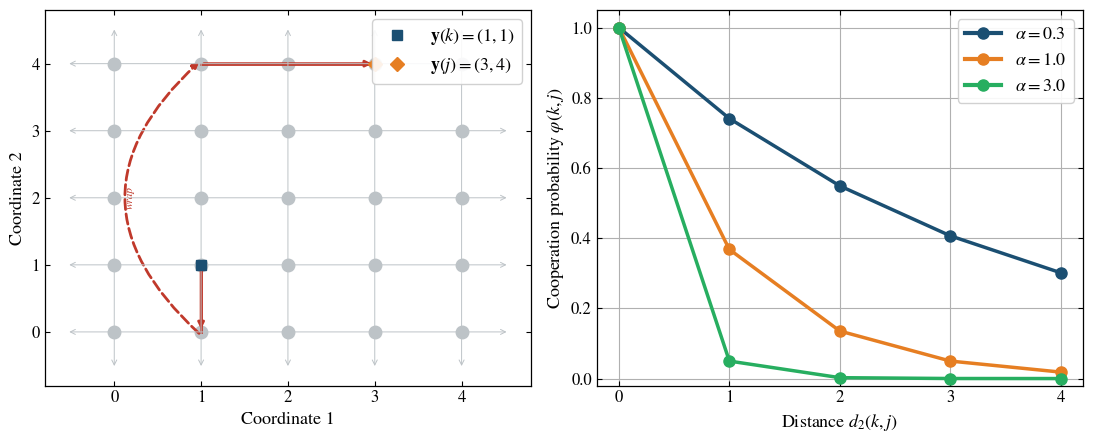

In [4]:
fig1, axes = plt.subplots(1, 2, figsize=(11, 4.5))

legend_fs = 13
legend_lw = 3.0
tick_fs   = 12

# ============================================================
# Left panel
# ============================================================
ax = axes[0]

L5 = 5
xs, ys = np.meshgrid(range(L5), range(L5))

ax.plot(
    xs.ravel(), ys.ravel(),
    "o",
    color="#bdc3c7",
    ms=9,
    ls="none",
    zorder=2
)

A, B = (1, 1), (3, 4)

ax.plot(
    *A,
    "s",
    color=COLORS[0],
    ms=7,
    zorder=5,
    label=r"$\mathbf{y}(k)=(1,1)$"
)

ax.plot(
    *B,
    "D",
    color=COLORS[1],
    ms=7,
    zorder=5,
    label=r"$\mathbf{y}(j)=(3,4)$"
)

path_c, lw_p = "#c0392b", 2.0

ax.plot(
    [1, 1], [1, 0],
    "-",
    color=path_c,
    lw=lw_p,
    zorder=3
)

ax.annotate(
    "",
    xy=(1, 0),
    xytext=(1, 1),
    arrowprops=dict(
        arrowstyle="-|>",
        color=path_c,
        lw=lw_p
    )
)

ax.annotate(
    "",
    xy=(1, 4.05),
    xytext=(1, -0.05),
    arrowprops=dict(
        arrowstyle="-|>",
        color=path_c,
        lw=lw_p,
        linestyle="dashed",
        connectionstyle="arc3,rad=-0.55"
    )
)

ax.text(
    0.12, 2.0,
    "wrap",
    fontsize=8,
    color=path_c,
    rotation=90,
    va="center",
    style="italic"
)

ax.plot(
    [1, 3], [4, 4],
    "-",
    color=path_c,
    lw=lw_p,
    zorder=3
)

ax.annotate(
    "",
    xy=(3, 4),
    xytext=(1, 4),
    arrowprops=dict(
        arrowstyle="-|>",
        color=path_c,
        lw=lw_p
    )
)

for i in range(L5):
    ax.annotate(
        "",
        xy=(i, -0.55),
        xytext=(i, L5 - 0.45),
        arrowprops=dict(
            arrowstyle="<->",
            color="#bdc3c7",
            lw=0.7
        )
    )

for j in range(L5):
    ax.annotate(
        "",
        xy=(-0.55, j),
        xytext=(L5 - 0.45, j),
        arrowprops=dict(
            arrowstyle="<->",
            color="#bdc3c7",
            lw=0.7
        )
    )

ax.set_xlim(-0.8, L5 - 0.2)
ax.set_ylim(-0.8, L5 - 0.2)

ax.set_xticks(range(L5))
ax.set_yticks(range(L5))

ax.set_xlabel("Coordinate 1", fontsize=13)
ax.set_ylabel("Coordinate 2", fontsize=13)

leg1 = ax.legend(
    loc="upper right",
    framealpha=0.9,
    prop={"size": legend_fs, "weight": "bold"}
)

for line in leg1.get_lines():
    line.set_linewidth(legend_lw)

ax.tick_params(axis="x", labelsize=tick_fs)
ax.tick_params(axis="y", labelsize=tick_fs)
ax.tick_params(**TICK_IN)


# ============================================================
# Right panel
# ============================================================
ax = axes[1]

d_max = 2 * (L5 // 2)
dv = np.arange(0, d_max + 1)

for k, alp in enumerate([0.3, 1.0, 3.0]):
    ax.plot(
        dv,
        np.exp(-alp * dv),
        "o-",
        color=COLORS[k],
        ms=8,
        lw=2.5,
        label=fr"$\alpha={alp}$"
    )

ax.set_xlabel(r"Distance $d_2(k,j)$", fontsize=13)
ax.set_ylabel(r"Cooperation probability $\varphi(k,j)$", fontsize=13)

leg2 = ax.legend(
    framealpha=0.9,
    prop={"size": legend_fs, "weight": "bold"}
)

for line in leg2.get_lines():
    line.set_linewidth(legend_lw)

ax.set_xticks(dv)
ax.set_ylim(-0.02, 1.05)

ax.tick_params(axis="x", labelsize=tick_fs)
ax.tick_params(axis="y", labelsize=tick_fs)
ax.tick_params(**TICK_IN)

ax.grid(True)

fig1.tight_layout()

save_figure(fig1, "fig1")

plt.show()

write_data('fig1_kernel.csv', ('L', 'n', 'alpha', 'distance', 'helping_probability'),
           ((L5, 2, alp, int(distance), np.exp(-alp*distance))
            for alp in (0.3, 1.0, 3.0) for distance in dv))


## Manuscript Figure 2 — threshold versus discrimination

$n=2$, $\mu=0.5$, $\nu=1$; $L=2,3,4,5,100$.
The 120 values of $\alpha$ range from $0.1$ to $5$. All thresholds use direct grouped finite sums.

Saved fig2.png and fig2.pdf


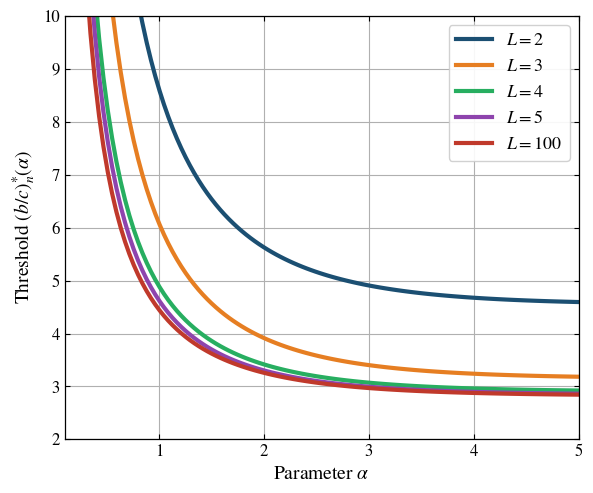

In [5]:
figure_rows = []
alpha_arr = np.linspace(0.1, 5.0, 120)
Lvals4    = [2,3, 4,5, 100]
lstyles4  = ["-","-","-", "-", "-"]

curve_lw = 3.0          # curve thickness
legend_fs = 13          # legend font size
legend_lw = 3.0         # legend line thickness

fig4, ax4 = plt.subplots(figsize=(6, 5))

for k, (Lv, ls) in enumerate(zip(Lvals4, lstyles4)):
    betas = np.array([threshold_periodic(al, Lv, 2, 0.5, 1.0) for al in alpha_arr])

    figure_rows.extend((Lv, 2, al, 0.5, 1.0, value) for al, value in zip(alpha_arr, betas))

    line, = ax4.plot(
        alpha_arr,
        betas,
        color=COLORS[k],
        ls=ls,
        lw=curve_lw,
        label=fr"$L={Lv}$"
    )


ax4.axhline(1.0, color="0.5", lw=1.2, ls=":")

ax4.set_xlabel(r"Parameter $\alpha$", fontsize=14)
ax4.set_ylabel(r"Threshold $(b/c)^{*}_{n}(\alpha)$", fontsize=14)

leg = ax4.legend(
    framealpha=0.9,
    fontsize=legend_fs,
    prop={"size": legend_fs, "weight": "bold"}
)

# Increase thickness of the sample lines shown inside the legend
for line in leg.get_lines():
    line.set_linewidth(legend_lw)

ax4.set_xlim(alpha_arr[0], alpha_arr[-1])
ax4.set_ylim(2, 10)

ax4.grid(True)

ax4.tick_params(axis="x", labelsize=12)
ax4.tick_params(axis="y", labelsize=12)

fig4.tight_layout()
save_figure(fig4, "fig2")

plt.show()

write_data('fig2.csv', THRESHOLD_COLUMNS, figure_rows)


## Manuscript Figure 3 — threshold versus dimension

$\alpha=1$, $\mu=0.5$, $\nu=1$; $L=2,3,4,5,100$ and integer $n=1,\ldots,10$.
The $L=100$, $n\ge4$ values use the bounded algebraic evaluation described above;
all other values use direct grouped finite sums. The dotted horizontal line is the reference value $3$.

Saved fig3.png and fig3.pdf


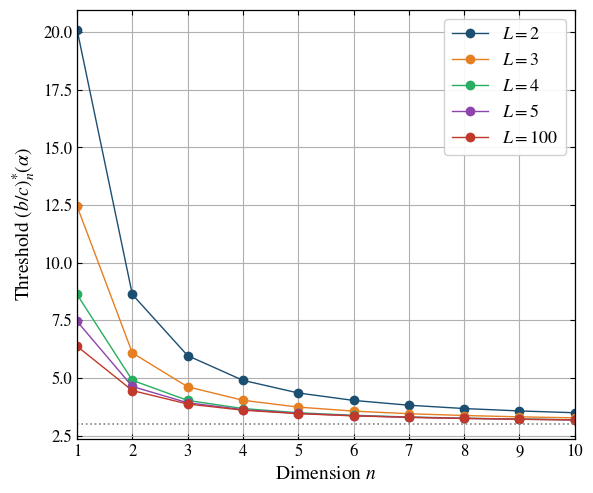

In [6]:
figure_rows = []
n_vals = np.arange(1, 11)   # n = 1,2,...,10

alpha_fixed = 1.0
Lvals5      = [2, 3, 4, 5, 100]
lstyles5    = ["-", "-", "-", "-", "-"]

curve_lw  = 1.0
legend_fs = 13
legend_lw = 1.0

fig5, ax5 = plt.subplots(figsize=(6, 5))

for k, (Lv, ls) in enumerate(zip(Lvals5, lstyles5)):

    betas = np.array([
        threshold_periodic(alpha_fixed, Lv, int(nv), 0.5, 1.0)
        for nv in n_vals
    ])

    figure_rows.extend((Lv, int(nv), alpha_fixed, 0.5, 1.0, value)
                       for nv, value in zip(n_vals, betas))

    ax5.plot(
        n_vals,
        betas,
        color=COLORS[k],
        ls=ls,
        lw=curve_lw,
        marker="o",
        label=fr"$L={Lv}$"
    )

ax5.axhline(3.0, color="0.5", lw=1.2, ls=":")

ax5.set_xlabel(r"Dimension $n$", fontsize=14)
ax5.set_ylabel(r"Threshold $(b/c)^{*}_{n}(\alpha)$", fontsize=14)

ax5.set_xticks(n_vals)

leg = ax5.legend(
    framealpha=0.9,
    fontsize=legend_fs,
    prop={"size": legend_fs, "weight": "bold"}
)

for line in leg.get_lines():
    line.set_linewidth(legend_lw)

ax5.set_xlim(n_vals[0], n_vals[-1])

ax5.grid(True)

ax5.tick_params(axis="x", labelsize=12)
ax5.tick_params(axis="y", labelsize=12)

fig5.tight_layout()

save_figure(fig5, "fig3")

plt.show()

write_data('fig3.csv', THRESHOLD_COLUMNS, figure_rows)


## Manuscript Figure 4 — threshold over discrimination and phenotype mutation

$L=5$, $n=2$, $\mu=0.5$; a $100\times100$ grid with
$\alpha\in[0.1,4]$ linearly spaced and $\nu\in[10^{-1},10^{2.5}]$ logarithmically spaced.
All values use direct finite sums. Colors saturate at $10$, while contour lines are calculated
from the **unclipped thresholds**. The raw grid is saved as `fig4_values.npz`.

Computing exact finite-sum 100x100 grid ...
Done.
Saved fig4.png and fig4.pdf


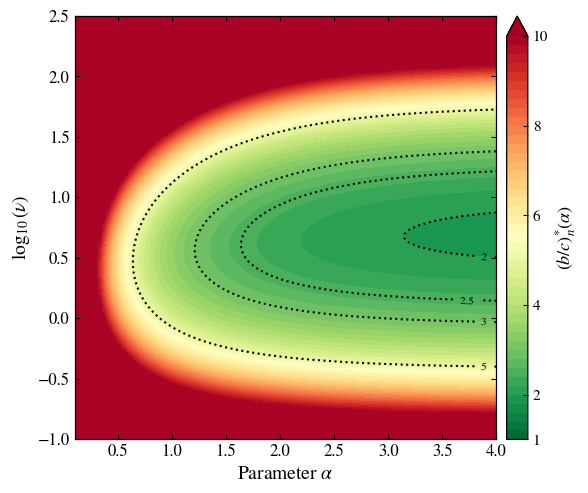

In [7]:
a_grid  = np.linspace(0.1, 4.0, 100)
nu_grid = np.logspace(-1, 2.5, 100)
AA, NN  = np.meshgrid(a_grid, nu_grid)
vmin, vmax = 1.0, 10.0
Lv = 5

print("Computing exact finite-sum 100x100 grid ...")
BB_raw = np.array([[threshold_periodic(al, Lv, 2, 0.5, nv) for al in a_grid] for nv in nu_grid])
BB_plot = np.clip(BB_raw, vmin, vmax)
print("Done.")

fig8, ax8 = plt.subplots(figsize=(6, 5))
pcm  = ax8.contourf(AA, np.log10(NN), BB_plot, levels=np.linspace(vmin, vmax, 46),
                    cmap=plt.cm.RdYlGn_r, vmin=vmin, vmax=vmax, extend="max")
cbar = fig8.colorbar(pcm, ax=ax8, pad=0.02)

cbar.set_ticks([1, 2, 4, 6, 8, 10])
cbar.ax.tick_params(labelsize=11)

cbar.set_label(r"$(b/c)^{*}_{n}(\alpha)$", fontsize=13)

clevels  = [1.5, 2.0, 2.5, 3.0, 5.0]
clstyles = [":",":", ":", ":", ":"]
clwidths = [1.5,1.5, 1.5, 1.5, 1.5]
clabels  = {1.5:r"$1.5$",2.0:r"$2$", 2.5:r"$2.5$", 3.0:r"$3$", 5.0:r"$5$"}
for lev, lsty, lw in zip(clevels, clstyles, clwidths):
    if np.nanmin(BB_raw) <= lev <= np.nanmax(BB_raw):
        cs = ax8.contour(AA, np.log10(NN), BB_raw, levels=[lev],
                        colors=["black"], linewidths=[lw], linestyles=[lsty])
        ax8.clabel(cs, fmt={lev: clabels[lev]}, fontsize=8, inline=True)

ax8.set_xlabel(r"Parameter $\alpha$", fontsize=14)
ax8.set_ylabel(r"$\log_{10}(\nu)$", fontsize=14)

ax8.tick_params(axis="x", labelsize=12)
ax8.tick_params(axis="y", labelsize=12)


fig8.tight_layout()
save_figure(fig8, "fig4")
plt.show()
np.savez_compressed(DATA_DIR / "fig4_values.npz", alpha=a_grid, nu=nu_grid, threshold=BB_raw)

write_data('fig4.csv', THRESHOLD_COLUMNS,
           ((Lv, 2, al, 0.5, nv, BB_raw[i, j])
            for i, nv in enumerate(nu_grid) for j, al in enumerate(a_grid)))


## Manuscript Figure 5 — threshold over discrimination and strategy mutation

$L=5$, $n=2$, $\nu=3$; a $120\times120$ grid with
$\alpha\in[0.1,4]$ linearly spaced and $\mu\in[10^{-2},10^{1.5}]$ logarithmically spaced.
All values use direct finite sums. The raw grid is saved as `fig5_values.npz`.

Computing exact finite-sum 120x120 grid over alpha and mu ...
Done.
Saved fig5.png and fig5.pdf


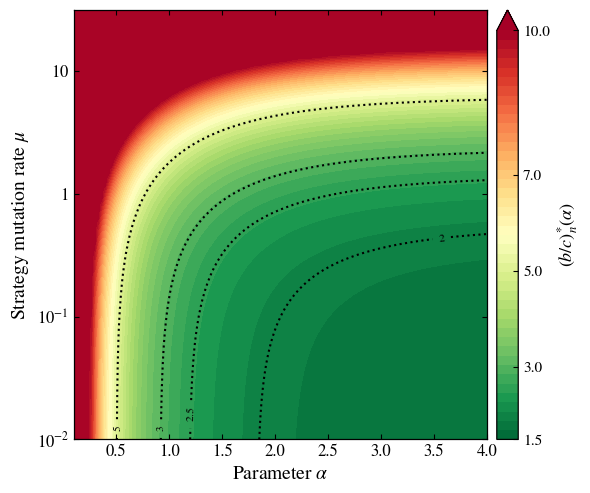

In [8]:
# ============================================================
# Threshold over discrimination and strategy mutation
# ============================================================

Lv       = 5
n_dim    = 2
nu_fixed = 3.0

a_grid  = np.linspace(0.1, 4.0, 120)
mu_grid = np.logspace(-2, 1.5, 120)

AA, MM = np.meshgrid(a_grid, mu_grid)

vmin, vmax = 1.5, 10.0

print("Computing exact finite-sum 120x120 grid over alpha and mu ...")

BB_raw = np.array([
    [threshold_periodic(al, Lv, n_dim, mu_val, nu_fixed) for al in a_grid]
    for mu_val in mu_grid
])

BB_plot = np.clip(BB_raw, vmin, vmax)

print("Done.")

fig_mu, ax_mu = plt.subplots(figsize=(6, 5))

pcm = ax_mu.contourf(
    AA,
    np.log10(MM),
    BB_plot,
    levels=np.linspace(vmin, vmax, 45),
    cmap=plt.cm.RdYlGn_r,
    vmin=vmin,
    vmax=vmax,
    extend="max"
)

cbar = fig_mu.colorbar(pcm, ax=ax_mu, pad=0.02)
cbar.set_label(r"$(b/c)^{*}_{n}(\alpha)$", fontsize=13)
cbar.set_ticks([1.5, 3, 5, 7, 10])
cbar.ax.tick_params(labelsize=11)

clevels  = [1.5,2.0, 2.5, 3.0, 5.0]

clstyles = [":", ":", ":", ":",":"]

clwidths = [1.5, 1.5, 1.5,1.5,1.5]

clabels  = {
    1.5: r"$1.5$",
    2.0: r"$2$",
    2.5: r"$2.5$",
    3.0: r"$3$",
    5.0: r"$5$"
}

for lev, lsty, lw in zip(clevels, clstyles, clwidths):
    if np.nanmin(BB_raw) <= lev <= np.nanmax(BB_raw):
        cs = ax_mu.contour(
            AA,
            np.log10(MM),
            BB_raw,
            levels=[lev],
            colors="black",
            linewidths=lw,
            linestyles=lsty
        )

        ax_mu.clabel(
            cs,
            fmt={lev: clabels[lev]},
            fontsize=8,
            inline=True
        )

ax_mu.set_xlabel(r"Parameter $\alpha$", fontsize=14)
ax_mu.set_ylabel(r"Strategy mutation rate $\mu$", fontsize=14)

yticks_mu = [1e-2, 1e-1, 1, 10]
ax_mu.set_yticks(np.log10(yticks_mu))
ax_mu.set_yticklabels(
    [r"$10^{-2}$", r"$10^{-1}$", r"$1$", r"$10$"],
    fontsize=9
)

ax_mu.tick_params(axis="x", labelsize=12)
ax_mu.tick_params(axis="y", labelsize=12)



fig_mu.tight_layout()
save_figure(fig_mu, "fig5")
plt.show()
np.savez_compressed(DATA_DIR / "fig5_values.npz", alpha=a_grid, mu=mu_grid, threshold=BB_raw)

write_data('fig5.csv', THRESHOLD_COLUMNS,
           ((Lv, n_dim, al, mv, nu_fixed, BB_raw[i, j])
            for i, mv in enumerate(mu_grid) for j, al in enumerate(a_grid)))


## fig5_threshold_vs_n — dimension at different discrimination strengths

$L=5$, $\mu=0.5$, $\nu=1$, $\alpha=0.3,0.5,4$, and integer $n=1,\ldots,10$.
All values use direct grouped finite sums.

Saved fig5_threshold_vs_n.png and fig5_threshold_vs_n.pdf


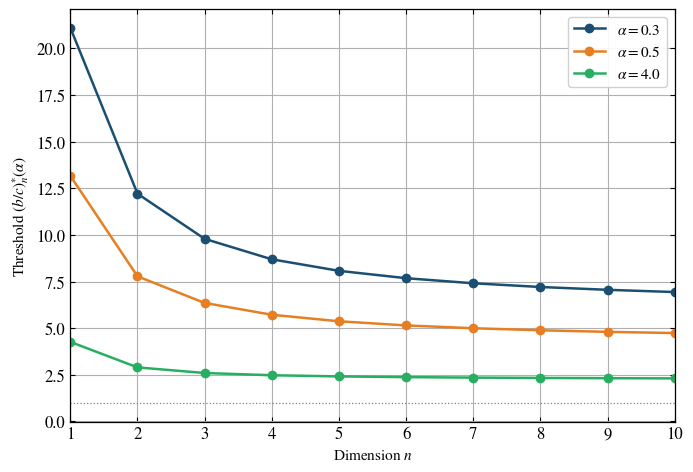

In [9]:
figure_rows = []
n_vals   = np.arange(1, 11)   # integers only: 1,2,...,10
alphas5  = [0.3, 0.5, 4.0]

fig5, ax5 = plt.subplots(figsize=(7, 4.8))
for k, alp in enumerate(alphas5):
    betas = [threshold_periodic(alp, 5, int(nv), 0.5, 1.0) for nv in n_vals]
    figure_rows.extend((5, int(nv), alp, 0.5, 1.0, value)
                       for nv, value in zip(n_vals, betas))
    ax5.plot(
        n_vals, betas,
        color=COLORS[k],
        marker="o",
        lw=1.8,
        label=fr"$\alpha={alp}$"
    )

ax5.axhline(1.0, color="0.5", lw=0.9, ls=":")
ax5.set_xlabel(r"Dimension $n$", fontsize=11)
ax5.set_ylabel(r"Threshold $(b/c)^{*}_{n}(\alpha)$", fontsize=11)
ax5.set_xticks(n_vals)
ax5.legend(fontsize=11, framealpha=0.9)
ax5.set_xlim(n_vals[0], n_vals[-1])
ax5.grid(True)
ax5.tick_params(axis="x", labelsize=12)
ax5.tick_params(axis="y", labelsize=12)
fig5.tight_layout()
save_figure(fig5, "fig5_threshold_vs_n")
plt.show()

write_data('fig5_threshold_vs_n.csv', THRESHOLD_COLUMNS, figure_rows)


## fig7_threshold_vs_L — threshold versus torus size

$n=2$, $\mu=0.5$, $\nu=1$, $\alpha=0.5,1.5,3$, and $L=2,\ldots,25$.
The vertical axis shows the threshold on a logarithmic scale, not a convergence gap.
All values use direct finite sums.

Saved fig7_threshold_vs_L.png and fig7_threshold_vs_L.pdf


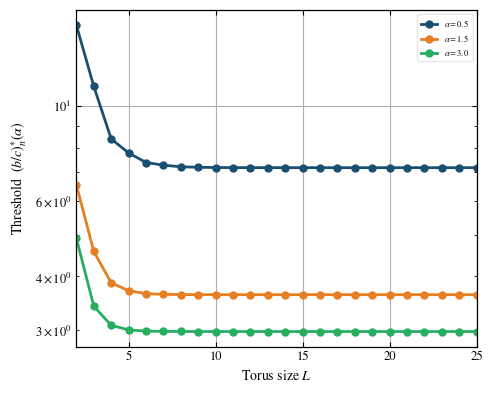

In [10]:
figure_rows = []
L_range = np.arange(2, 26)
fig7, ax7 = plt.subplots(figsize=(5, 4))
for k, alp in enumerate([0.5, 1.5, 3.0]):
    bL  = np.array([threshold_periodic(alp, int(Lv), 2, 0.5, 1.0) for Lv in L_range])
    figure_rows.extend((int(Lv), 2, alp, 0.5, 1.0, value)
                       for Lv, value in zip(L_range, bL))
    ax7.semilogy(L_range, bL, "o-", color=COLORS[k], ms=5, label=fr"$\alpha={alp}$")
ax7.set_xlabel(r"Torus size $L$")
ax7.set_ylabel(r"Threshold  $(b/c)^{*}_{n}(\alpha)$")
ax7.legend(fontsize=6, framealpha=0.5)
ax7.set_xlim(L_range[0], L_range[-1]); ax7.grid(True)
fig7.tight_layout()
save_figure(fig7, "fig7_threshold_vs_L")
plt.show()

write_data('fig7_threshold_vs_L.csv', THRESHOLD_COLUMNS, figure_rows)


## Save numerical checks

In [11]:
summary = {
    'release_version': '1.0.0',
    'python': sys.version.split()[0],
    'numpy': np.__version__, 'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__,
    'direct_grouped_term_budget': DIRECT_MAX_TERMS,
    'algebraic_series_relative_tolerance': SERIES_REL_TOL,
    'validation_comparisons': len(validation_records),
    'maximum_validation_relative_difference': max(r['relative_difference'] for r in validation_records),
    'threshold_evaluation_counts_including_validation': dict(METHOD_COUNTS),
    'figures': sorted(p.name for p in FIGURE_DIR.glob('*.png')),
    'data_tables': DATA_TABLES,
}
(CHECK_DIR / 'validation_results.json').write_text(json.dumps(validation_records, indent=2) + '\n')
(CHECK_DIR / 'series_certificates.json').write_text(json.dumps(list(SERIES_CERTIFICATES.values()), indent=2) + '\n')
(CHECK_DIR / 'run_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
print(f"Saved {len(summary['figures'])} figures and {len(DATA_TABLES)} data tables.")
print(f"All {len(validation_records)} numerical comparisons passed.")


Saved 7 figures and 7 data tables.
All 18 numerical comparisons passed.
